In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"C:\Users\Pranav Morye\OneDrive\Desktop\nyc classification\AB_NYC_2019.csv")
df.head()


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
print(df.shape)
print(df.describe(include="all"))

(48895, 16)
                  id            name       host_id host_name  \
count   4.889500e+04           48879  4.889500e+04     48874   
unique           NaN           47905           NaN     11452   
top              NaN  Hillside Hotel           NaN   Michael   
freq             NaN              18           NaN       417   
mean    1.901714e+07             NaN  6.762001e+07       NaN   
std     1.098311e+07             NaN  7.861097e+07       NaN   
min     2.539000e+03             NaN  2.438000e+03       NaN   
25%     9.471945e+06             NaN  7.822033e+06       NaN   
50%     1.967728e+07             NaN  3.079382e+07       NaN   
75%     2.915218e+07             NaN  1.074344e+08       NaN   
max     3.648724e+07             NaN  2.743213e+08       NaN   

       neighbourhood_group neighbourhood      latitude     longitude  \
count                48895         48895  48895.000000  48895.000000   
unique                   5           221           NaN           NaN   
top

In [5]:
missing=print(df.isnull().sum())
missing = df.isnull().sum()
missing[missing > 0]

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

In [6]:
df["room_type"].unique()

<ArrowStringArray>
['Private room', 'Entire home/apt', 'Shared room']
Length: 3, dtype: str

<Axes: xlabel='room_type', ylabel='count'>

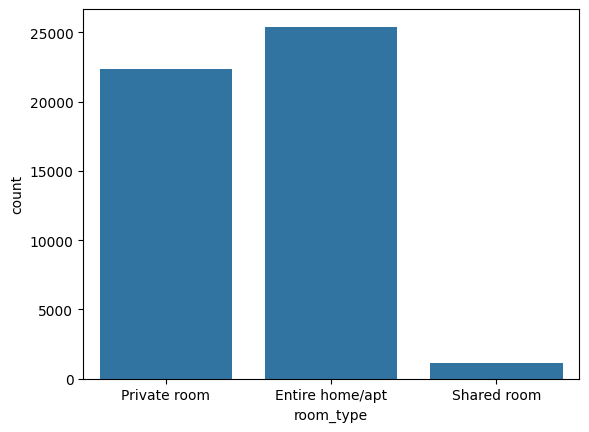

In [7]:
df["room_type"].value_counts()
sns.countplot(x="room_type",data=df)

class is imbance-share class small

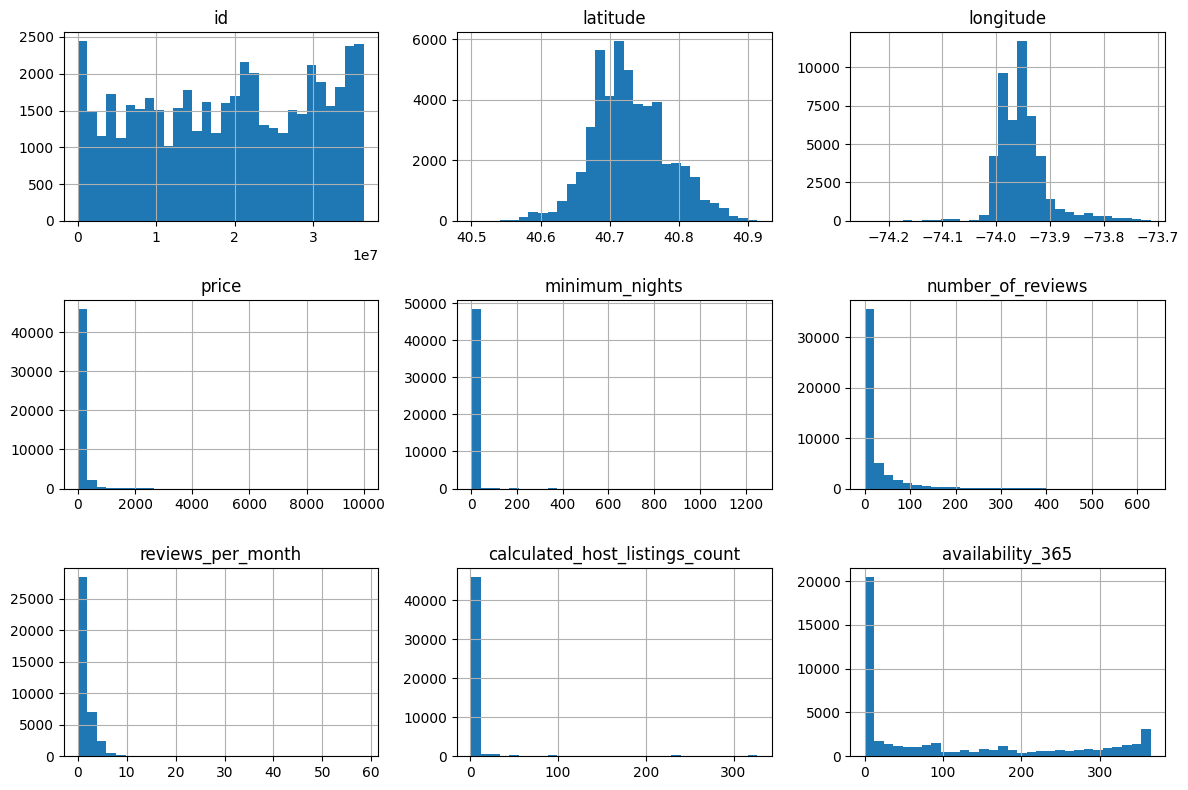

In [8]:
numerical_col = df.select_dtypes(include="number").columns.drop("host_id","id")
df[numerical_col].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()


<Axes: xlabel='neighbourhood_group', ylabel='count'>

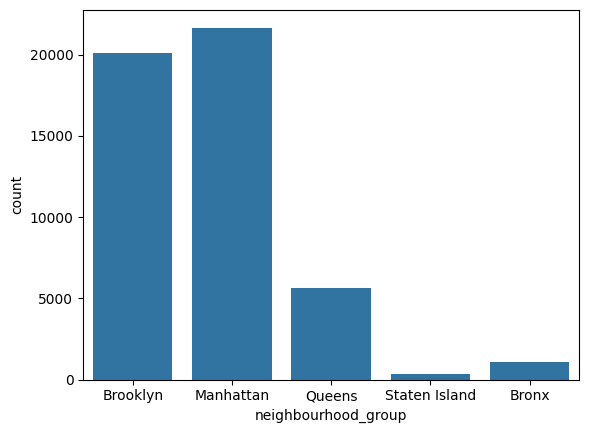

In [9]:
sns.countplot(data=df,x="neighbourhood_group")

bivarient analysis

<Axes: xlabel='room_type', ylabel='price'>

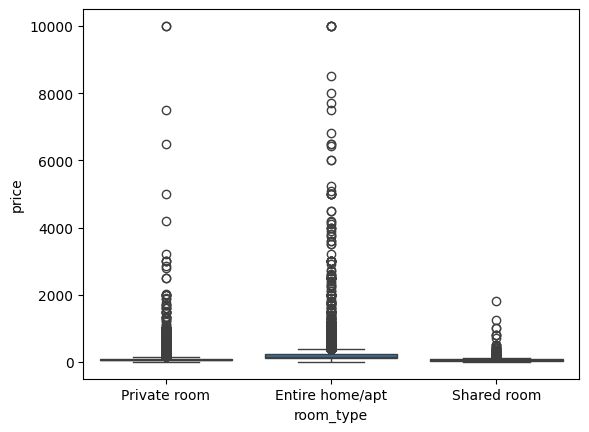

In [10]:
sns.boxplot(x="room_type",y="price",data=df)

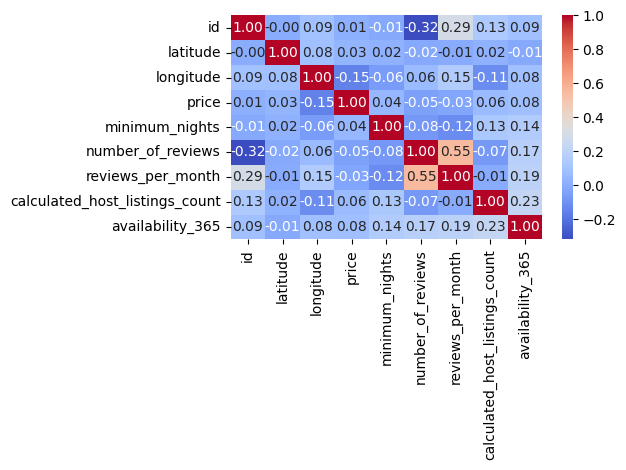

In [11]:
corr = df[numerical_col].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.tight_layout()
plt.show()

<Axes: xlabel='longitude', ylabel='latitude'>

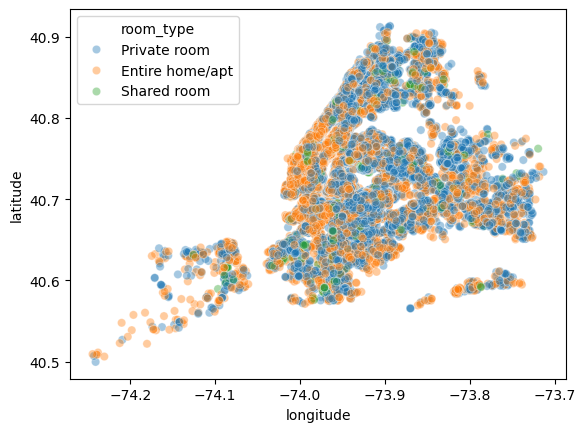

In [12]:
sns.scatterplot(
    x="longitude",
    y="latitude",
    data=df,
    hue="room_type",
    alpha=0.4
)

data cleaning and freture  enginering

In [13]:
df_clean= df.drop(columns=["id","name","host_id","last_review"])


df_clean["reviews_per_month"]=df_clean["reviews_per_month"].fillna(0)
df_clean.head()


#cap extreme  outlier 
price_cap=df_clean["price"].quantile(0.99)
night_cap=df_clean["minimum_nights"].quantile(0.99)

df_clean['price']=df_clean["price"].clip(upper=price_cap)
df_clean['minimum_nights'] = df_clean["minimum_nights"].clip(upper=night_cap)

df_clean

,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
48890,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,0.00,2,9
48891,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,0.00,2,36
48892,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,0.00,1,27
48893,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,0.00,6,2


In [ ]:
X=df_clean.drop(columns=["room_type"])
y= df_clean["room_type"]


import numpy as np

rng = np.random.RandomState(42)
train_indices = []
test_indices = []

for room_type in y.unique():
     indices = np.flatnonzero(y.to_numpy() == room_type)
     rng.shuffle(indices)

     test_count = min(
          len(indices) - 1,
          max(1, int(np.ceil(len(indices) * 0.33)))
     )
     test_indices.extend(indices[:test_count])
     train_indices.extend(indices[test_count:])

rng.shuffle(train_indices)
rng.shuffle(test_indices)

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]
y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]


statify ensure when train test split each group(class) in original prportion

In [16]:
numerical_col=["latitude","longitude","minium_night","number_of_review",
               "review_per_moth","calculate_host_lising_count","avaliblity_365"]

catogrical_col=[""]